# Installation



**Conda Environment**
- conda create -n openai-cloud
- conda activate openai-cloud
- conda install -c conda-forge "openai>=1.2.4" ipykernel jupyterlab notebook python=3.10

**Install Pytorch and other packages:**
- python -m pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
- python -m pip install openai pillow numpy opencv-python jiwer
- python -m pip install torch torchvision torchaudio matplotlib pandas pillow requests

**Verify:**
python -c "import torch; print(torch.cuda.is_available()); print(torch.cuda.get_device_name(0))"

**Registers your environment as a Jupyter kernel:**
python -m ipykernel install --user --name=openai-cloud


**Note:**
by using api, cuda or NVIDIA GPU is not required.


In [2]:
#!pip install openai pillow numpy opencv-python jiwer
#!pip install torch torchvision torchaudio matplotlib pandas pillow requests jiwer

In [1]:
from openai import OpenAI
import os

client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])

In [56]:
#import os
#print(os.getenv("OPENAI_API_KEY"))

In [2]:
import sys
import torch

print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Torch CUDA:", torch.version.cuda)

Torch version: 2.7.1+cu118
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Torch CUDA: 11.8


In [3]:
import torch
from PIL import Image
import matplotlib.pyplot as plt
import requests
import pandas as pd
import re
from jiwer import wer, cer

# Image Download

In [4]:
import os
import platform

pages = [8, 9, 12, 38, 53, 78, 94, 105, 114, 115,
         210, 314, 316, 384, 457, 468, 490, 619, 615, 753]

base = "https://nlp.fi.muni.cz/projekty/ahisto/book_by_id/494/"

os.makedirs("images", exist_ok=True)
os_type = platform.system()
print("OS: ", os_type)

for p in pages:
    path = f"images/{p}.jpg"
    
    if not os.path.exists(path):
        if os_type == "Windows":
            # !curl -o {path} {base}{p}.jpg
            !curl -k -L -o {path} {base}{p}.jpg # ignore certificate verification, follow redirects
        else:
            !wget -O {path} {base}{p}.jpg
    else:
        print(f"Already exists: {path}")

OS:  Windows
Already exists: images/8.jpg
Already exists: images/9.jpg
Already exists: images/12.jpg
Already exists: images/38.jpg
Already exists: images/53.jpg
Already exists: images/78.jpg
Already exists: images/94.jpg
Already exists: images/105.jpg
Already exists: images/114.jpg
Already exists: images/115.jpg
Already exists: images/210.jpg
Already exists: images/314.jpg
Already exists: images/316.jpg
Already exists: images/384.jpg
Already exists: images/457.jpg
Already exists: images/468.jpg
Already exists: images/490.jpg
Already exists: images/619.jpg
Already exists: images/615.jpg
Already exists: images/753.jpg


# GPT OCR - Prompt and Function

In [5]:
prompt_text_1 = "Extract all text from this image exactly as written. Preserve line breaks."

In [6]:
prompt_text_0 = """
You are an OCR specialist.

Extract every visible character from this image exactly as it appears.

Return plain text only. Preserve the original reading order, line breaks, paragraph breaks, headings, punctuation, capitalization, spelling, abbreviations, umlauts, ß, Roman numerals, page numbers, and hyphenation exactly as printed.

Do not correct spelling or grammar. Do not modernize, normalize, translate, summarize, explain, or infer missing text. Do not merge words that are split by line-ending hyphens.

If any character or word cannot be read with confidence, write [illegible] exactly at that position instead of guessing.

Do not include any comments, Markdown, labels, or additional text. Return only the transcription.
"""

In [7]:
import base64

def run_ocr_one_image(image_path, prompt_text):
    with open(image_path, "rb") as f:
        image_bytes = f.read()

    image_base64 = base64.b64encode(image_bytes).decode("utf-8")

    response = client.responses.create(
        model="gpt-5.4",
        max_output_tokens=1500,
        input=[{
            "role": "user",
            "content": [
                {"type": "input_text", "text": prompt_text},
                {
                    "type": "input_image",
                    "image_url": f"data:image/jpeg;base64,{image_base64}"
                }
            ]
        }]
    )

    return response.output_text

# Experiment 1 - Clean Baseline
Original image to OCR, Without preprocessing

In [8]:
import os

output_dir = "outputs/Experiment_1"
os.makedirs(output_dir, exist_ok=True)

In [133]:
for p in pages:
    print(f"\n==============================")
    print(f"Page {p}")
    print(f"==============================")

    image_path = f"images/{p}.jpg"
    output_path = os.path.join(output_dir, f"page_{p}.txt")

    output_text = run_ocr_one_image(image_path, prompt_text_0)

    print(output_text)

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(output_text)

    print(f"Saved: {output_path}")


Page 8
Vorwort.

Das Jahr 1885 brachte die erste Fortsetzung des K. Ruprecht mit dem zweiten
Bande von dessen Regierung, dem fünften der ganzen Reihe. Im Jahr 1887 wurde
die dritte Abtheilung der Zeit K. Sigmund’s ausgegeben, der neunte Band der Reichs-
tagsakten. Jetzt nach einem Jahre können wir bereits den sechsten Band mittheilen,
welcher zugleich der dritte und Schlußband K. Ruprecht’s ist. Hiermit schließt sich die
Lücke, welche in der Regierung dieses Königs noch auszufüllen war, und die sämmt-
lichen bisher erschienenen neun Bände bilden eine ununterbrochene Kette. Mit dem
zehnten Bande, dessen Ausgabe das nächste sein wird, soll dann auch die Periode K.
Sigmund’s zu ihrem Ende kommen.

I. Bearbeitung des vorliegenden Bandes.

Die Leitung des Unternehmens ruht wie bisher in der Hand H. v. Sybel’s. Von
früheren Mitarbeitern des Bandes, welche bei den Vorarbeiten überhaupt sowie ins-
besondere bei der Anfertigung von Regesten Auszügen und Abschriften thätig waren,
sind zu nennen

### Evaluation Experiment 1

In [9]:
def normalize_text(text):
    text = text.lower()
    text = text.strip()
    text = re.sub(r"\s+", " ", text)
    return text

In [10]:
results_exp1 = []

gold_base = "https://nlp.fi.muni.cz/projekty/ahisto/ocr-output/494/"

for p in pages:
    print(f"Evaluating page {p}...")

    gold_url = f"{gold_base}{p}.txt"
    gold_text = requests.get(gold_url).text

    pred_path = os.path.join(output_dir, f"page_{p}.txt")
    with open(pred_path, "r", encoding="utf-8") as f:
        pred_text = f.read()

    gold_norm = normalize_text(gold_text)
    pred_norm = normalize_text(pred_text)

    #compute metrics
    wer_score = wer(gold_norm, pred_norm)
    cer_score = cer(gold_norm, pred_norm)

    results_exp1.append({
        "page": p,
        "WER": wer_score,
        "CER": cer_score
    })

Evaluating page 8...
Evaluating page 9...
Evaluating page 12...
Evaluating page 38...
Evaluating page 53...
Evaluating page 78...
Evaluating page 94...
Evaluating page 105...
Evaluating page 114...
Evaluating page 115...
Evaluating page 210...
Evaluating page 314...
Evaluating page 316...
Evaluating page 384...
Evaluating page 457...
Evaluating page 468...
Evaluating page 490...
Evaluating page 619...
Evaluating page 615...
Evaluating page 753...


In [11]:
print("=== Experiment 1 Results: GPT5.4 ===")
df_exp1 = pd.DataFrame(results_exp1)
df_exp1

=== Experiment 1 Results: GPT5.4 ===


,page,WER,CER
0,8,0.027295,0.004464
1,9,0.014235,0.002704
2,12,0.028169,0.009204
3,38,0.139466,0.038073
4,53,0.093878,0.020644
5,78,0.076259,0.023216
6,94,0.220539,0.096486
7,105,0.125237,0.055396
8,114,0.118483,0.044772
9,115,0.050571,0.024938


In [12]:
mean_wer = df_exp1["WER"].mean()
mean_cer = df_exp1["CER"].mean()

print("=== Experiment 1 Results ===")
print(f"Mean WER: {mean_wer:.4f}")
print(f"Mean CER: {mean_cer:.4f}")

=== Experiment 1 Results ===
Mean WER: 0.0828
Mean CER: 0.0302


### Save result

In [13]:
import os

output_dir_result_1 = "outputs/Results"
os.makedirs(output_dir_result_1, exist_ok=True)

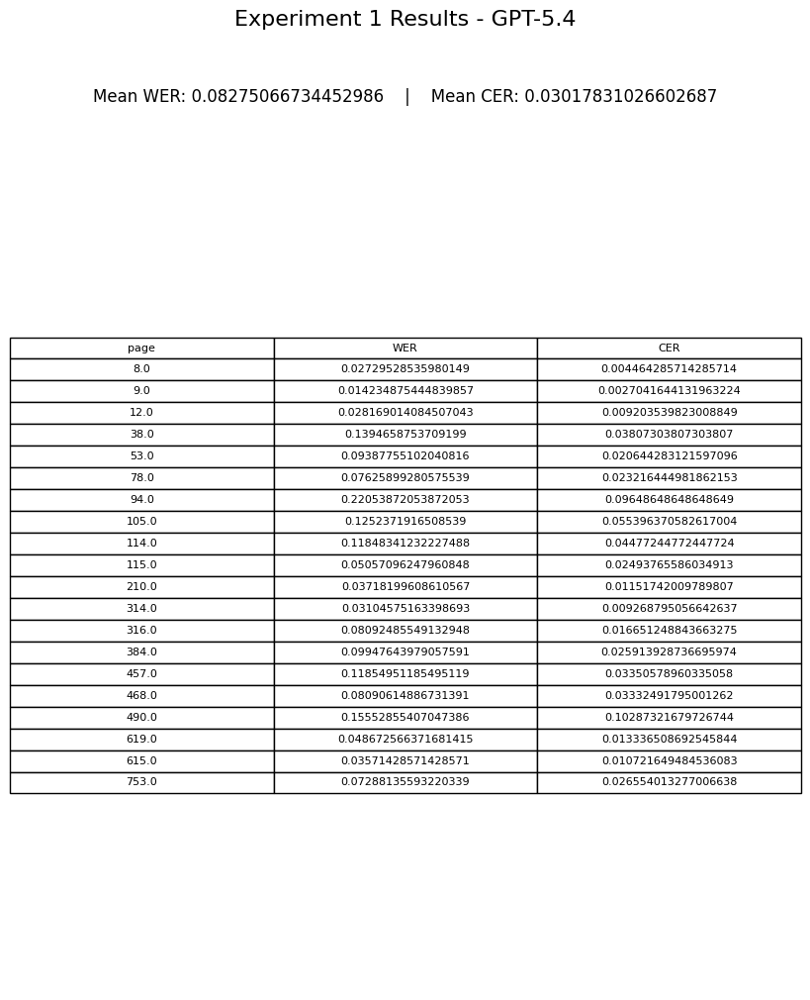

Saved: outputs/Results\experiment_1_results.png


In [14]:
import os
import matplotlib.pyplot as plt

mean_wer = df_exp1["WER"].mean()
mean_cer = df_exp1["CER"].mean()

save_path = os.path.join(output_dir_result_1, "experiment_1_results.png")

fig, ax = plt.subplots(figsize=(10, len(df_exp1) * 0.45 + 2))
ax.axis("off")


fig.suptitle("Experiment 1 Results - GPT-5.4", fontsize=16, y=0.98)

summary_text = f"Mean WER: {mean_wer}    |    Mean CER: {mean_cer}"
fig.text(0.5, 0.90, summary_text, ha="center", va="center", fontsize=12)

# Table
table = ax.table(
    cellText=df_exp1.values,
    colLabels=df_exp1.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.3)

ax.set_position([0.1, 0.08, 0.8, 0.78])

fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

print("Saved:", save_path)

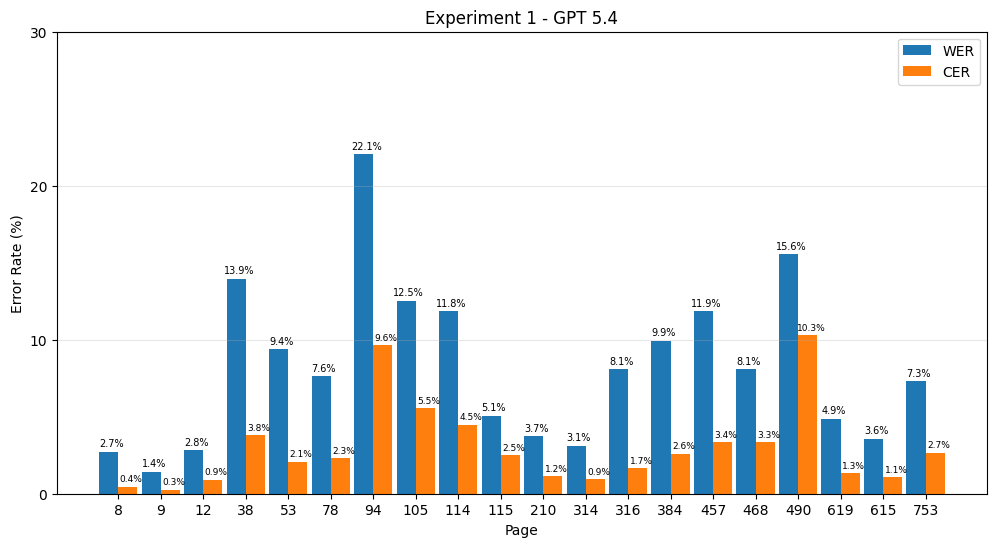

In [15]:
import numpy as np
x = np.arange(len(df_exp1))
width = 0.45

wer_pct = df_exp1["WER"] * 100
cer_pct = df_exp1["CER"] * 100

plt.figure(figsize=(12,6))

bars1 = plt.bar(x - width/2, wer_pct, width, label="WER")
bars2 = plt.bar(x + width/2, cer_pct, width, label="CER")

for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.06,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=7
    )
for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.08,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=6.5
    )

plt.xticks(x, df_exp1["page"])
plt.xlabel("Page")
plt.ylabel("Error Rate (%)")
plt.title("Experiment 1 - GPT 5.4")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.ylim(0, 30)
plt.yticks(np.arange(0, 31, 10))

os.makedirs(output_dir_result_1, exist_ok=True)

plt.savefig(
    os.path.join(
        output_dir_result_1,
        "experiment_1_wer_cer_by_page.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Experiment 2 - Noise
Salt and Pepper, Nosify, Distortion - Without Preprocessing

In [16]:
import os

output_dir_2 = "outputs/Experiment_2"
os.makedirs(output_dir_2, exist_ok=True)

### Salt and Pepper Function

Salt-and-pepper noise was implemented based on standard image processing techniques as described in (https://www.geeksforgeeks.org/python/add-a-salt-and-pepper-noise-to-an-image-with-python/)

In [17]:
import numpy as np
from PIL import Image


# amount = how many pixels change
# amount = 0.2 -- 20% pixel changed, amount = 0.8 -- 80% pixel changed
# salt_vs_pepper = how many are white
# salt_vs_pepper = 0.2 -- 20% white, salt_vs_pepper = 0.8 -- 80% white


def add_salt_pepper(image, amount=0.005, salt_vs_pepper=0.5):

    img = np.array(image).copy()
    h, w = img.shape[:2]

    num_pixels = int(amount * h * w)
    num_salt = int(num_pixels * salt_vs_pepper)
    num_pepper = num_pixels - num_salt

    #salt -white
    ys = np.random.randint(0, h, num_salt)
    xs = np.random.randint(0, w, num_salt)
    img[ys, xs] = 255

    #pepper -black
    ys = np.random.randint(0, h, num_pepper)
    xs = np.random.randint(0, w, num_pepper)
    img[ys, xs] = 0

    return Image.fromarray(img)

### Image_Distortion
The image distortion functions are adapted from the Image_Distortion repository(https://github.com/namks/Image_Distortion/tree/main), specifically the zoom and resolution degradation methods.

In [19]:
from PIL import Image

def zoom_img(image, zoom_scale=1.15):
    w, h = image.size
    x = w / 2
    y = h / 2

    cropped = image.crop((
        x - w / (2 * zoom_scale),
        y - h / (2 * zoom_scale),
        x + w / (2 * zoom_scale),
        y + h / (2 * zoom_scale)
    ))

    return cropped.resize((w, h), Image.BICUBIC)

def lower_res_img(image, scale=0.7):
    w, h = image.size
    low_res = image.resize((int(w * scale), int(h * scale)), Image.BICUBIC)
    return low_res.resize((w, h), Image.BICUBIC)

def add_image_distortion(image, zoom_scale=1.15, resolution_scale=0.7):
    image = zoom_img(image, zoom_scale=zoom_scale)
    image = lower_res_img(image, scale=resolution_scale)
    return image

### Noisy
Additional blurring effects were applied to simulate realistic degradation, inspired by data augmentation techniques such as Noisify
(https://github.com/dstl/Noisify)

In [20]:
import cv2
import numpy as np
from PIL import Image

def add_blur(image, kernel_size=3):
    img = np.array(image)
    blurred = cv2.GaussianBlur(img, (kernel_size, kernel_size), 0)
    return Image.fromarray(blurred)

### Testing one image with Noise

#### Test Salt and Pepper

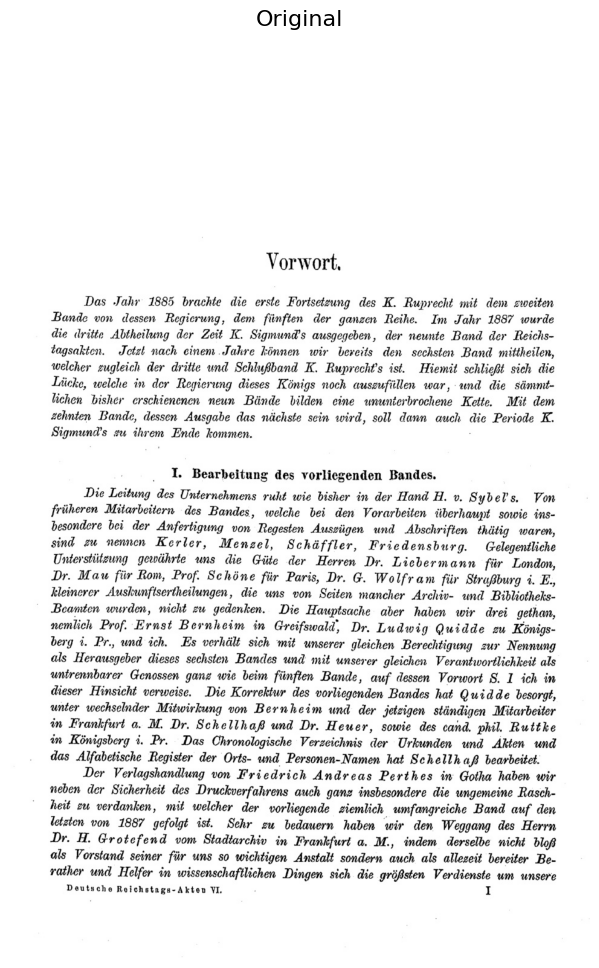

In [21]:
from PIL import Image
import matplotlib.pyplot as plt

noise_image_test = "images/8.jpg"

img = Image.open(noise_image_test).convert("RGB")

plt.figure(figsize=(10,12))
plt.imshow(img)
plt.title("Original", fontsize=16)
plt.axis("off")
plt.show()

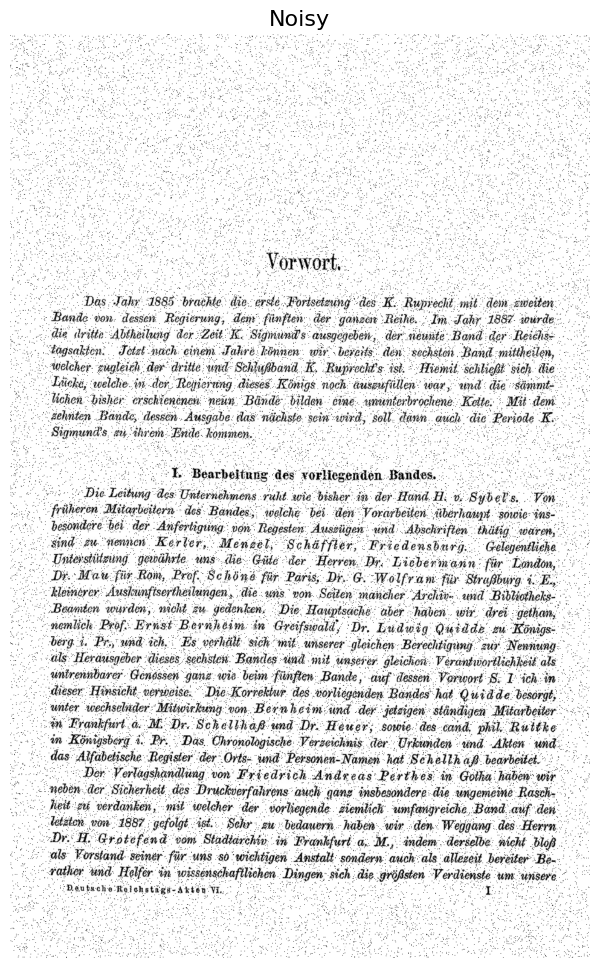

In [22]:
noisy_img = add_salt_pepper(img, amount=0.04,salt_vs_pepper=0.3)
plt.figure(figsize=(10,12))
plt.imshow(noisy_img)
plt.title("Noisy", fontsize=16)
plt.axis("off")
plt.show()

#### Test Image Distortion and BLurr

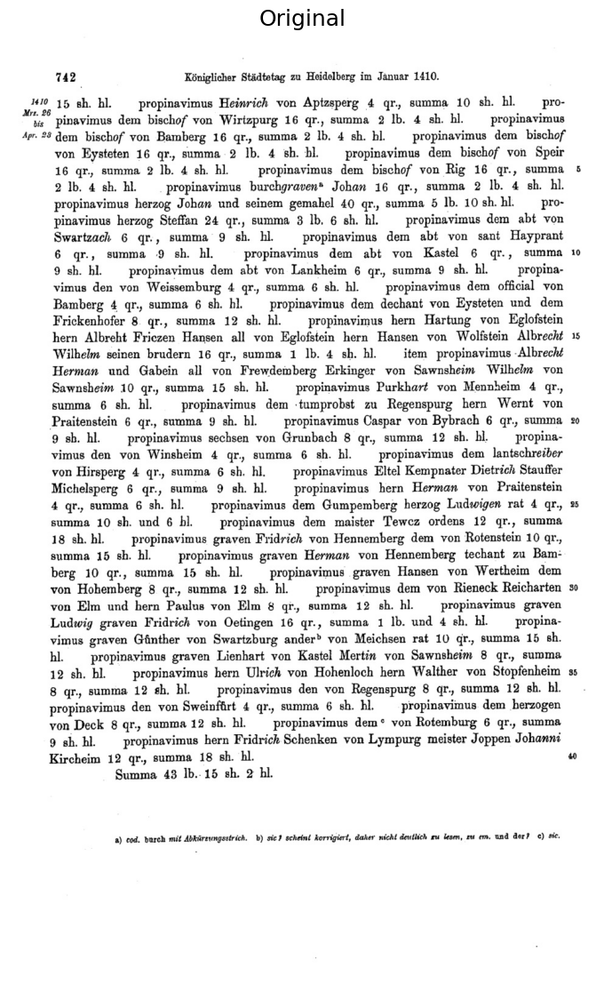

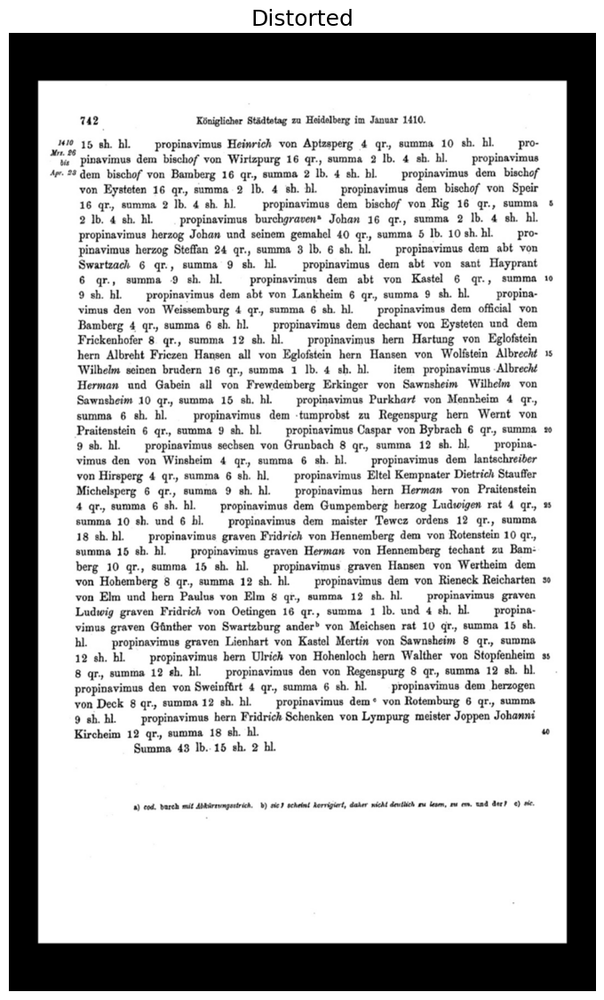

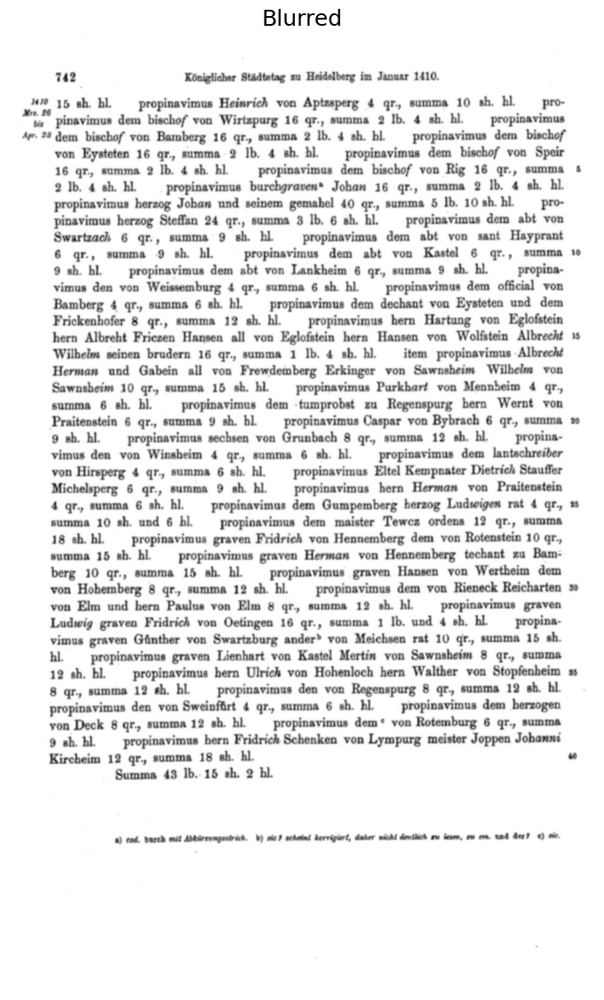

In [23]:
from PIL import Image
import matplotlib.pyplot as plt

noise_image_test2 = "images/753.jpg"
img1 = Image.open(noise_image_test2).convert("RGB")

#fixed zoom_scale
distorted_img = add_image_distortion(
    img1,
    zoom_scale=0.9,
    resolution_scale=0.8
)


blurred_img = add_blur(img1, kernel_size=5)

#original
plt.figure(figsize=(10,14))
plt.imshow(img1)
plt.title("Original", fontsize=18)
plt.axis("off")
plt.show()

#distorted
plt.figure(figsize=(10,14))
plt.imshow(distorted_img)
plt.title("Distorted", fontsize=18)
plt.axis("off")
plt.show()

#blur
plt.figure(figsize=(10,14))
plt.imshow(blurred_img)
plt.title("Blurred", fontsize=18)
plt.axis("off")
plt.show()

### Combining Three Functions
- add salt_pepper
- add image_distortion
- add blurr

In [24]:
def apply_all_corruptions(image,sp_amount=0.005,sp_ratio=0.5,zoom_scale=1.15,resolution_scale=0.7,
                          blur_kernel=3):
    image = add_salt_pepper(
        image,
        amount=sp_amount,
        salt_vs_pepper=sp_ratio
    )

    image = add_image_distortion(
        image,
        zoom_scale=zoom_scale,
        resolution_scale=resolution_scale
    )

    image = add_blur(
        image,
        kernel_size=blur_kernel
    )

    return image

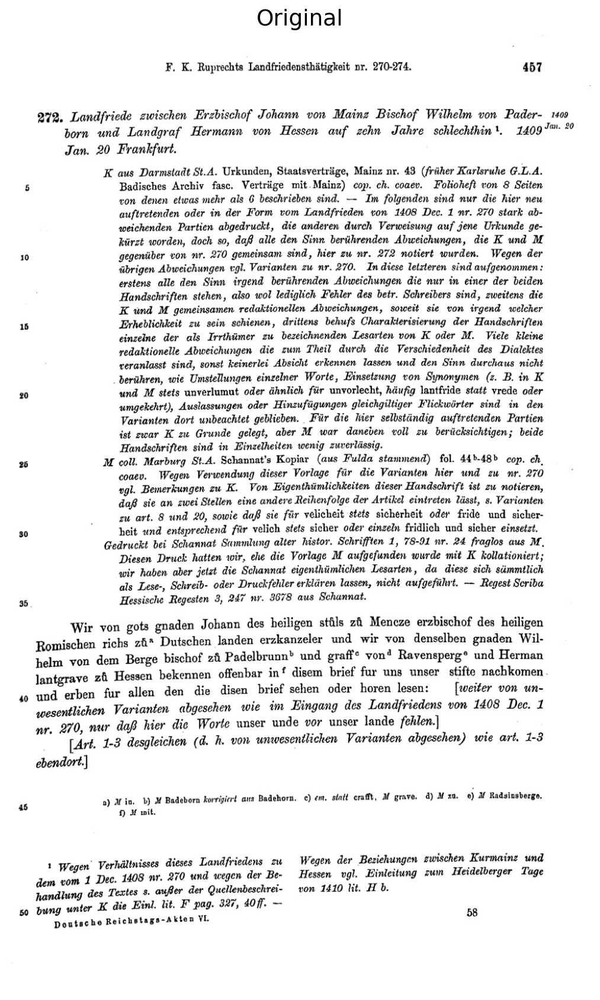

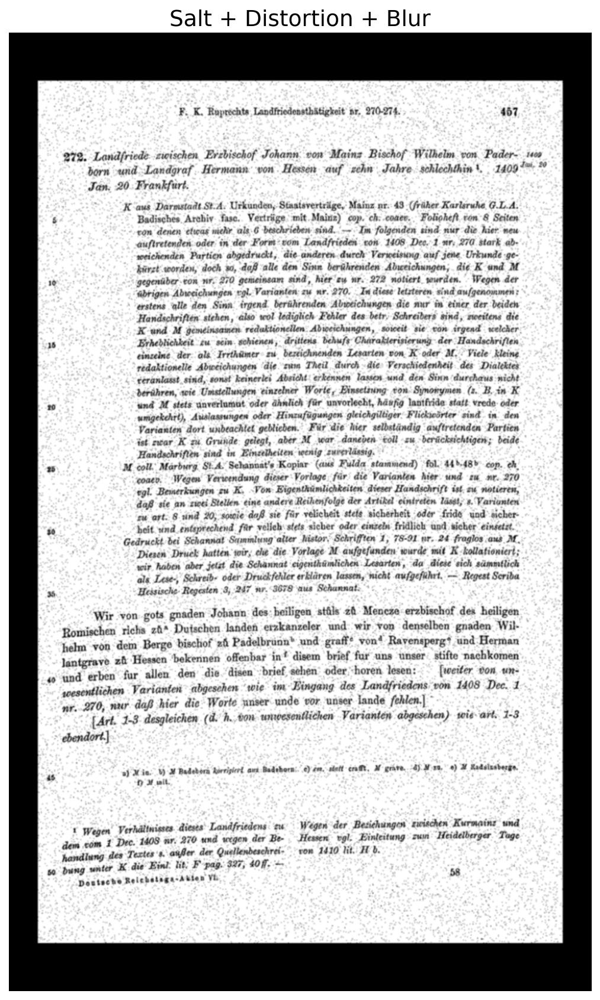

In [25]:
noise_image_test = "images/468.jpg"

img = Image.open(noise_image_test).convert("RGB")
combined_img = apply_all_corruptions(
    img,
    sp_amount=0.04,
    sp_ratio=0.4,
    zoom_scale=0.9,
    resolution_scale = 0.85,
    blur_kernel=3
)
#original
plt.figure(figsize=(10,14), dpi=150)
plt.imshow(img)
plt.title("Original", fontsize=18)
plt.axis("off")
plt.show()

#combined
plt.figure(figsize=(10,14), dpi=150)
plt.imshow(combined_img)
plt.title("Salt + Distortion + Blur", fontsize=18)
plt.axis("off")
plt.show()

### Apply corruption for all images

In [27]:
import os
os.makedirs("corrupted_images", exist_ok=True)

In [26]:
from PIL import Image

for p in pages:
    img = Image.open(f"images/{p}.jpg").convert("RGB")

    combined_img = apply_all_corruptions(
        img,
        sp_amount=0.04,
        sp_ratio=0.4,
        zoom_scale=0.9,
        resolution_scale=0.85,
        blur_kernel=3
    )

    combined_img.save(f"corrupted_images/{p}.jpg")

print("Done saving all corrupted images.")

Done saving all corrupted images.


In [52]:
for p in pages:
    print(f"\n==============================")
    print(f"Page {p}")
    print(f"==============================")

    image_path = f"corrupted_images/{p}.jpg"
    output_path = os.path.join(output_dir_2, f"page_{p}.txt")

    output_text = run_ocr_one_image(image_path, prompt_text_0)

    print(output_text)

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(output_text)

    print(f"Saved: {output_path}")


Page 8
Vorwort.

Das Jahr 1885 brachte die erste Fortsetzung des K. Ruprecht mit dem zweiten
Bande von dessen Regierung, dem fünften der ganzen Reihe. Im Jahr 1887 wurde
die dritte Abtheilung der Zeit K. Sigmund's ausgegeben, der neunte Band der Reichs-
tagsakten. Jetzt nach einem Jahre können wir bereits den sechsten Band mittheilen,
welcher zugleich der dritte und Schlußband K. Ruprechts ist. Hiermit schließt sich die
Lücke, welche in der Regierung dieses Königs noch auszufüllen war, und die sämmt-
lichen bisher erschienenen neun Bände bilden eine ununterbrochene Kette. Mit dem
zehnten Bande, dessen Ausgabe das nächste sein wird, soll dann auch die Periode K.
Sigmund's zu ihrem Ende kommen.

I. Bearbeitung des vorliegenden Bandes.
Die Leitung des Unternehmens ruht wie bisher in der Hand H. v. Sybel's. Von
früheren Mitarbeitern des Bandes, welche bei den Vorarbeiten überhaupt sowie ins-
besondere bei der Anfertigung von Regesten, Auszügen und Abschriften thätig waren,
sind zu nennen 

### Evaluation - Experiment 2

In [27]:
def normalize_text(text):
    text = text.lower()
    text = text.strip()
    text = re.sub(r"\s+", " ", text)
    return text

In [28]:
results_exp2 = []

gold_base = "https://nlp.fi.muni.cz/projekty/ahisto/ocr-output/494/"

for p in pages:
    print(f"Evaluating Experiment 2 - page {p}...")

    gold_url = f"{gold_base}{p}.txt"
    gold_text = requests.get(gold_url).text

    pred_path = os.path.join(output_dir_2, f"page_{p}.txt")
    with open(pred_path, "r", encoding="utf-8") as f:
        pred_text = f.read()

    gold_norm = normalize_text(gold_text)
    pred_norm = normalize_text(pred_text)

    #compute metrics
    wer_score = wer(gold_norm, pred_norm)
    cer_score = cer(gold_norm, pred_norm)

    results_exp2.append({
        "page": p,
        "WER": wer_score,
        "CER": cer_score
    })

Evaluating Experiment 2 - page 8...
Evaluating Experiment 2 - page 9...
Evaluating Experiment 2 - page 12...
Evaluating Experiment 2 - page 38...
Evaluating Experiment 2 - page 53...
Evaluating Experiment 2 - page 78...
Evaluating Experiment 2 - page 94...
Evaluating Experiment 2 - page 105...
Evaluating Experiment 2 - page 114...
Evaluating Experiment 2 - page 115...
Evaluating Experiment 2 - page 210...
Evaluating Experiment 2 - page 314...
Evaluating Experiment 2 - page 316...
Evaluating Experiment 2 - page 384...
Evaluating Experiment 2 - page 457...
Evaluating Experiment 2 - page 468...
Evaluating Experiment 2 - page 490...
Evaluating Experiment 2 - page 619...
Evaluating Experiment 2 - page 615...
Evaluating Experiment 2 - page 753...


In [29]:
print("=== Experiment 2 Results -GPT5.4 ===")
df_exp2 = pd.DataFrame(results_exp2)
df_exp2

=== Experiment 2 Results -GPT5.4 ===


,page,WER,CER
0,8,0.042184,0.008185
1,9,0.056940,0.011898
2,12,0.077465,0.020885
3,38,0.290801,0.122248
4,53,0.180952,0.055127
5,78,0.200000,0.071826
6,94,0.318182,0.131892
7,105,0.201139,0.063356
8,114,0.150079,0.052645
9,115,0.070147,0.032419


In [30]:
mean_wer_exp2 = df_exp2["WER"].mean()
mean_cer_exp2 = df_exp2["CER"].mean()

print("=== Experiment 2 Results ===")
print(f"Mean WER: {mean_wer_exp2:.4f}")
print(f"Mean CER: {mean_cer_exp2:.4f}")

=== Experiment 2 Results ===
Mean WER: 0.1336
Mean CER: 0.0480


### Save Result

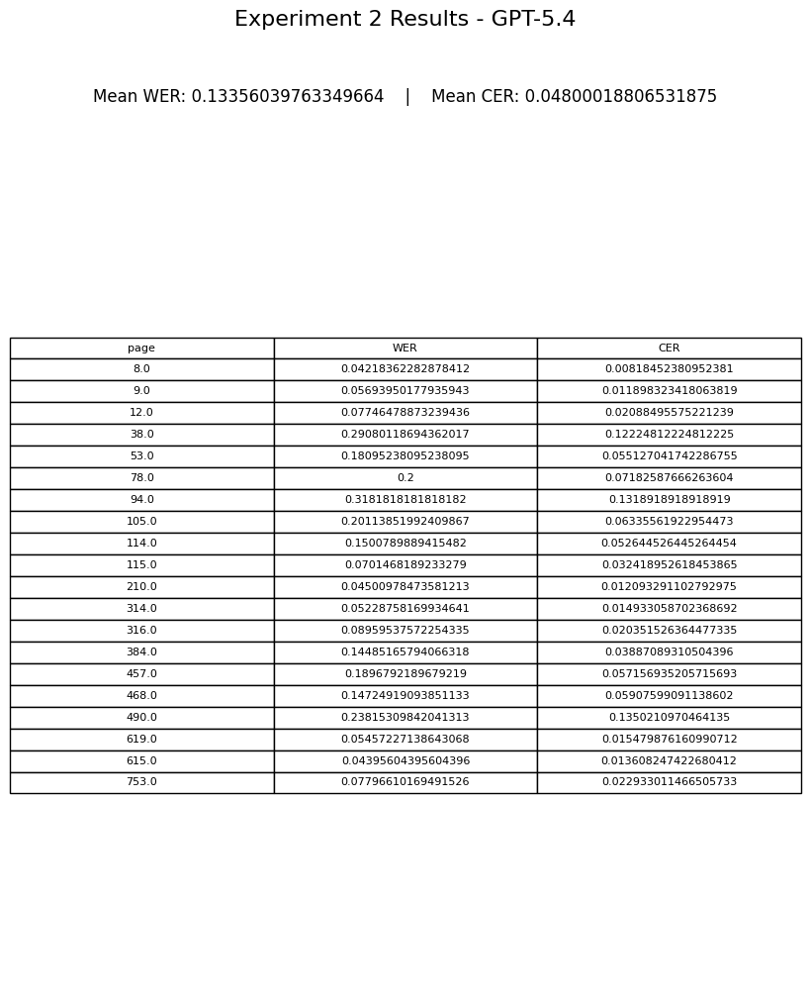

Saved: outputs/Results\experiment_2_results.png


In [31]:
import os
import matplotlib.pyplot as plt

mean_wer = df_exp2["WER"].mean()
mean_cer = df_exp2["CER"].mean()

save_path = os.path.join(output_dir_result_1, "experiment_2_results.png")

fig, ax = plt.subplots(figsize=(10, len(df_exp2) * 0.45 + 2))
ax.axis("off")


fig.suptitle("Experiment 2 Results - GPT-5.4", fontsize=16, y=0.98)

summary_text = f"Mean WER: {mean_wer}    |    Mean CER: {mean_cer}"
fig.text(0.5, 0.90, summary_text, ha="center", va="center", fontsize=12)


table = ax.table(
    cellText=df_exp2.values,
    colLabels=df_exp2.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.3)

ax.set_position([0.1, 0.08, 0.8, 0.78])

fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

print("Saved:", save_path)

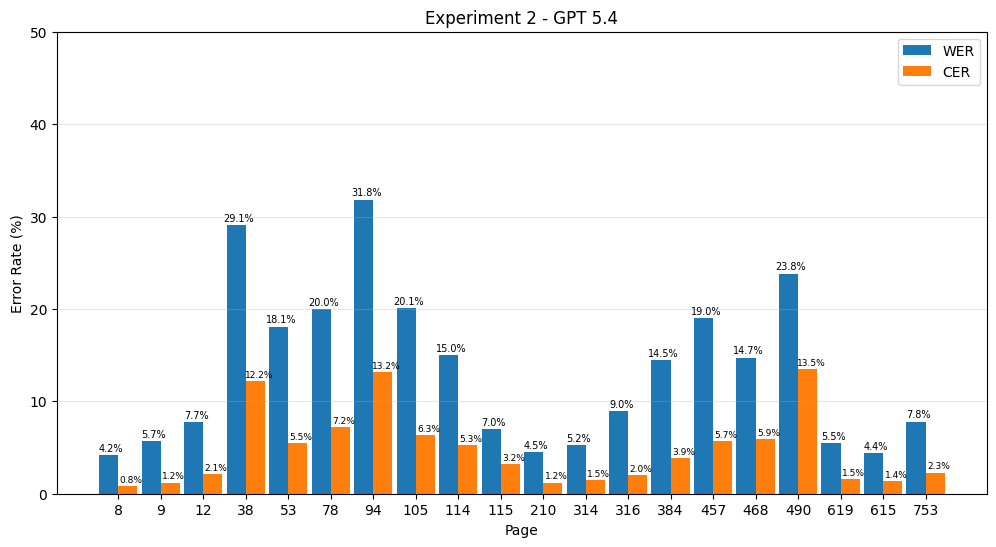

In [32]:
import numpy as np
x = np.arange(len(df_exp2))
width = 0.45

wer_pct = df_exp2["WER"] * 100
cer_pct = df_exp2["CER"] * 100

plt.figure(figsize=(12,6))

bars1 = plt.bar(x - width/2, wer_pct, width, label="WER")
bars2 = plt.bar(x + width/2, cer_pct, width, label="CER")

for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.06,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=7
    )
for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.08,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=6.5
    )

plt.xticks(x, df_exp2["page"])
plt.xlabel("Page")
plt.ylabel("Error Rate (%)")
plt.title("Experiment 2 - GPT 5.4")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.ylim(0, 50)
plt.yticks(np.arange(0, 51, 10))

os.makedirs(output_dir_result_1, exist_ok=True)

plt.savefig(
    os.path.join(
        output_dir_result_1,
        "experiment_2_wer_cer_by_page.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Experiment 3 - With Preprocessing

In [33]:
import os

output_dir_3 = "outputs/Experiment_3"
os.makedirs(output_dir_3, exist_ok=True)

### Preprocessing function

In [45]:
import cv2
import numpy as np
from PIL import Image

def preprocess_image_v3(image):
    img = np.array(image.convert("RGB"))
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    upscaled = cv2.resize(
        gray,
        None,
        fx=1,
        fy=1,
        interpolation=cv2.INTER_LANCZOS4
    )


    enhanced = cv2.convertScaleAbs(upscaled, alpha=1.15, beta=2)

    result = enhanced.copy()
    text_mask = result < 190
    result[text_mask] = np.clip(result[text_mask] * 0.75, 0, 255)

    blur = cv2.GaussianBlur(result, (0, 0), 0.8)
    result = cv2.addWeighted(result, 1.4, blur, -0.4, 0)

    result[result > 240] = 255

    return Image.fromarray(result)

### test preprocessing on one image

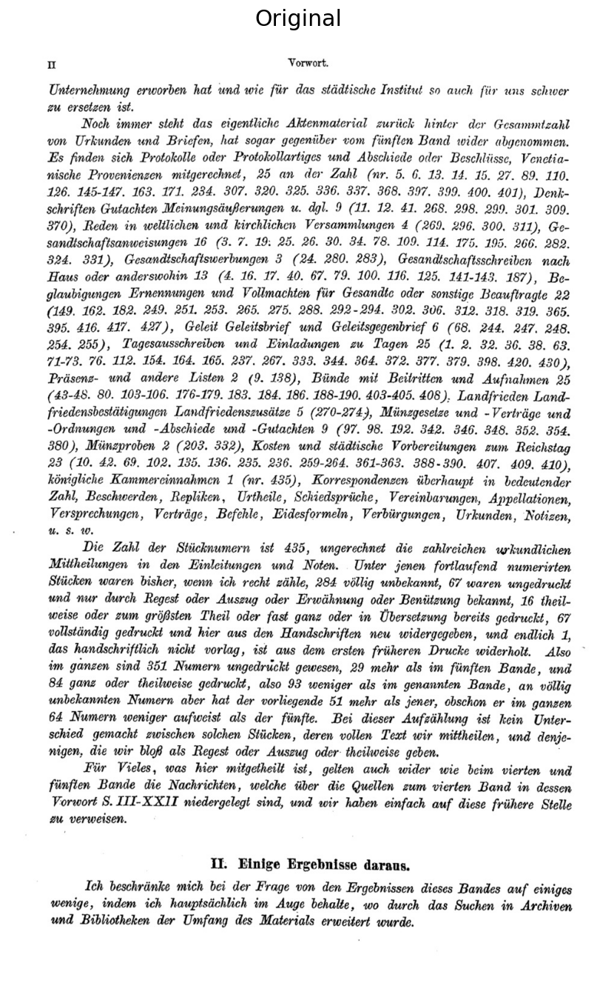

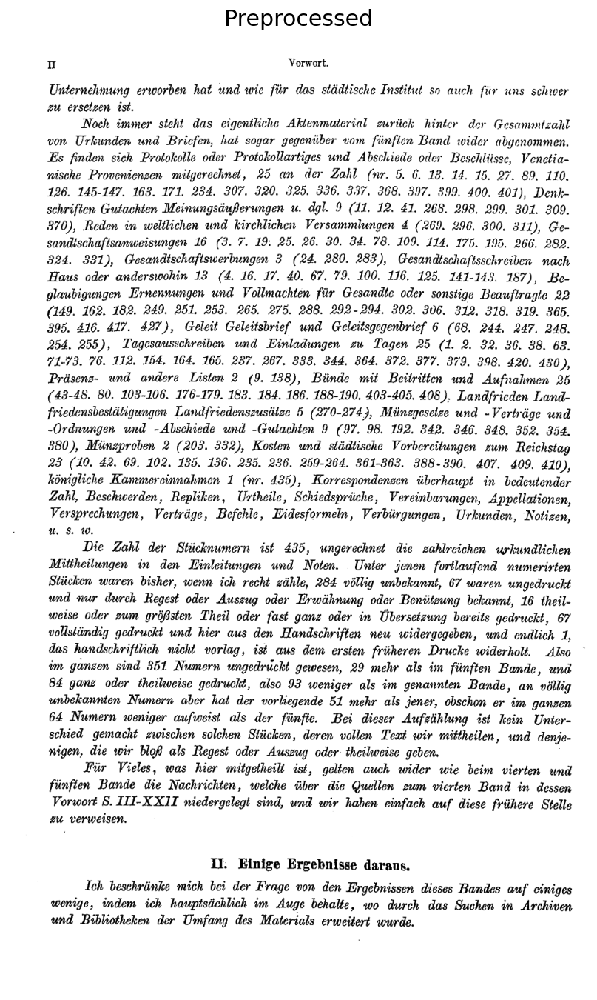

In [35]:
from PIL import Image
import matplotlib.pyplot as plt

test_image_path = "images/9.jpg"

img = Image.open(test_image_path).convert("RGB")
preprocessed_img = preprocess_image_v3(img)

plt.figure(figsize=(10,14), dpi=120)
plt.imshow(img)
plt.title("Original", fontsize=18)
plt.axis("off")
plt.show()

plt.figure(figsize=(10,14), dpi=120)
plt.imshow(preprocessed_img, cmap="gray")
plt.title("Preprocessed", fontsize=18)
plt.axis("off")
plt.show()

In [36]:
import os

os.makedirs("preprocessed_images", exist_ok=True)

### Apply preprocessing to all original images

In [46]:
from PIL import Image

for p in pages:
    img = Image.open(f"images/{p}.jpg").convert("RGB")

    preprocessed_img = preprocess_image_v3(img)

    preprocessed_img.save(f"preprocessed_images/{p}.jpg")

print("Done saving all preprocessed images.")

Done saving all preprocessed images.


### Run GPT OCR on preprocessed images

In [188]:
for p in pages:
    print(f"\n==============================")
    print(f"Page {p}")
    print(f"==============================")

    image_path = f"preprocessed_images/{p}.jpg"
    output_path = os.path.join(output_dir_3, f"page_{p}.txt")

    output_text = run_ocr_one_image(image_path, prompt_text_0)

    print(output_text)

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(output_text)

    print(f"Saved: {output_path}")


Page 8
Vorwort.

Das Jahr 1885 brachte die erste Fortsetzung des K. Rupprecht mit dem zweiten
Bande von dessen Regierung, dem fünften der ganzen Reihe. Im Jahr 1887 wurde
die dritte Abtheilung der Zeit K. Sigmund's ausgegeben, der neunte Band der Reichs-
tagsakten. Jetzt nach einem Jahre können wir bereits den sechsten Band mittheilen,
welcher zugleich der dritte und Schlußband K. Rupprecht's ist. Hiermit schließt sich die
Lücke, welche in der Regierung dieses Königs noch auszufüllen war, und die sämmt-
lichen bisher erschienenen neun Bände bilden eine ununterbrochene Kette. Mit dem
zehnten Bande, dessen Ausgabe das nächste sein wird, soll dann auch die Periode K.
Sigmund's zu ihrem Ende kommen.

I. Bearbeitung des vorliegenden Bandes.

Die Leitung des Unternehmens ruht wie bisher in der Hand H. v. Sybel's. Von
früheren Mitarbeitern des Bandes, welche bei den Vorarbeiten überhaupt sowie ins-
besondere bei der Anfertigung von Regesten Auszügen und Abschriften thätig waren,
sind zu nenn

### Evaluation -Experiment 3

In [78]:
def normalize_text(text):
    text = text.lower()
    text = text.strip()
    text = re.sub(r"\s+", " ", text)
    return text

In [79]:
results_exp3 = []

gold_base = "https://nlp.fi.muni.cz/projekty/ahisto/ocr-output/494/"

for p in pages:
    print(f"Evaluating Experiment 3 - page {p}...")

    gold_url = f"{gold_base}{p}.txt"
    gold_text = requests.get(gold_url).text

    pred_path = os.path.join(output_dir_3, f"page_{p}.txt")
    with open(pred_path, "r", encoding="utf-8") as f:
        pred_text = f.read()

    gold_norm = normalize_text(gold_text)
    pred_norm = normalize_text(pred_text)

    wer_score = wer(gold_norm, pred_norm)
    cer_score = cer(gold_norm, pred_norm)

    results_exp3.append({
        "page": p,
        "WER": wer_score,
        "CER": cer_score
    })

Evaluating Experiment 3 - page 8...
Evaluating Experiment 3 - page 9...
Evaluating Experiment 3 - page 12...
Evaluating Experiment 3 - page 38...
Evaluating Experiment 3 - page 53...
Evaluating Experiment 3 - page 78...
Evaluating Experiment 3 - page 94...
Evaluating Experiment 3 - page 105...
Evaluating Experiment 3 - page 114...
Evaluating Experiment 3 - page 115...
Evaluating Experiment 3 - page 210...
Evaluating Experiment 3 - page 314...
Evaluating Experiment 3 - page 316...
Evaluating Experiment 3 - page 384...
Evaluating Experiment 3 - page 457...
Evaluating Experiment 3 - page 468...
Evaluating Experiment 3 - page 490...
Evaluating Experiment 3 - page 619...
Evaluating Experiment 3 - page 615...
Evaluating Experiment 3 - page 753...


In [80]:
print("=== Experiment 3 Results -GPT5.4 ===")
df_exp3 = pd.DataFrame(results_exp3)
df_exp3

=== Experiment 3 Results -GPT5.4 ===


,page,WER,CER
0,8,0.022333,0.003720
1,9,0.016014,0.002975
2,12,0.039906,0.011327
3,38,0.149852,0.039886
4,53,0.061224,0.012704
5,78,0.097842,0.037243
6,94,0.234007,0.099730
7,105,0.311195,0.205030
8,114,0.118483,0.044772
9,115,0.044046,0.023940


In [81]:
mean_wer_exp3 = df_exp3["WER"].mean()
mean_cer_exp3 = df_exp3["CER"].mean()

print("=== Experiment 3 Results ===")
print(f"Mean WER: {mean_wer_exp3:.4f}")
print(f"Mean CER: {mean_cer_exp3:.4f}")

=== Experiment 3 Results ===
Mean WER: 0.0852
Mean CER: 0.0349


### Save Result

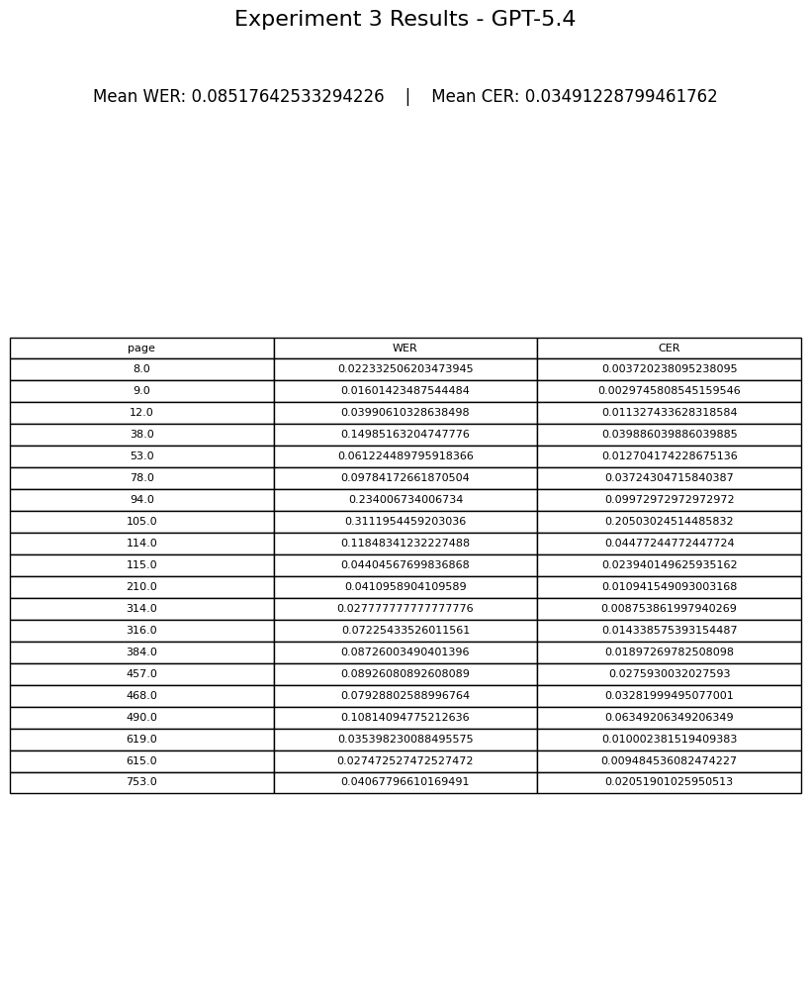

Saved: outputs/Results\experiment_3_results.png


In [82]:
import os
import matplotlib.pyplot as plt

mean_wer = df_exp3["WER"].mean()
mean_cer = df_exp3["CER"].mean()

save_path = os.path.join(output_dir_result_1, "experiment_3_results.png")

fig, ax = plt.subplots(figsize=(10, len(df_exp3) * 0.45 + 2))
ax.axis("off")


fig.suptitle("Experiment 3 Results - GPT-5.4", fontsize=16, y=0.98)

summary_text = f"Mean WER: {mean_wer}    |    Mean CER: {mean_cer}"
fig.text(0.5, 0.90, summary_text, ha="center", va="center", fontsize=12)

# Table
table = ax.table(
    cellText=df_exp3.values,
    colLabels=df_exp3.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.3)

ax.set_position([0.1, 0.08, 0.8, 0.78])

fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

print("Saved:", save_path)

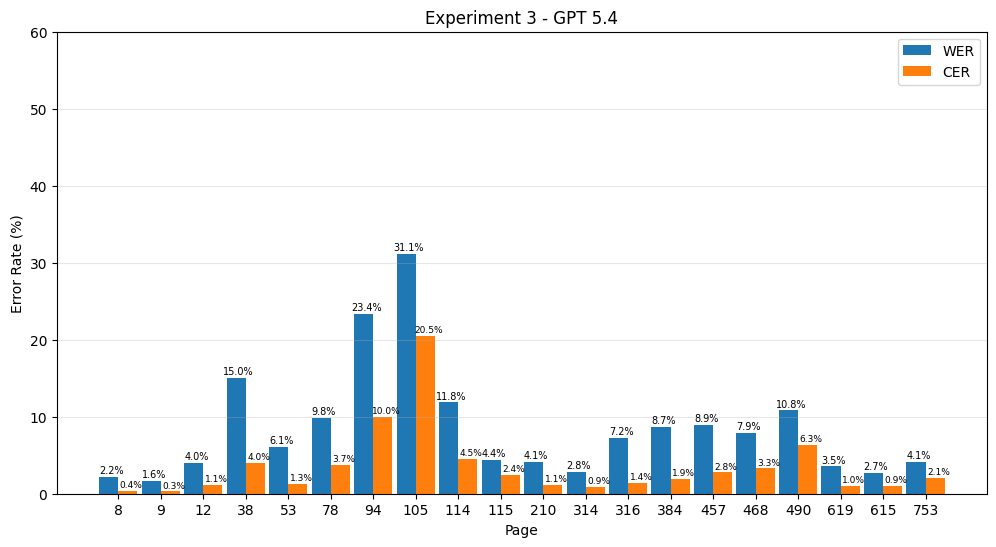

In [83]:
import numpy as np
x = np.arange(len(df_exp3))
width = 0.45

wer_pct = df_exp3["WER"] * 100
cer_pct = df_exp3["CER"] * 100

plt.figure(figsize=(12,6))

bars1 = plt.bar(x - width/2, wer_pct, width, label="WER")
bars2 = plt.bar(x + width/2, cer_pct, width, label="CER")

for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.06,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=7
    )
for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.08,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=6.5
    )

plt.xticks(x, df_exp3["page"])
plt.xlabel("Page")
plt.ylabel("Error Rate (%)")
plt.title("Experiment 3 - GPT 5.4")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.ylim(0, 60)
plt.yticks(np.arange(0, 61, 10))

os.makedirs(output_dir_result_1, exist_ok=True)

plt.savefig(
    os.path.join(
        output_dir_result_1,
        "experiment_3_wer_cer_by_page.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Experiment 4: With Noise and Preprocessing

In [196]:
import os

output_dir_4 = "outputs/Experiment_4"
os.makedirs(output_dir_4, exist_ok=True)

### Create folder for noisy + preprocessed images

In [104]:
import os

os.makedirs("corrupted_preprocessed_images", exist_ok=True)

In [105]:
import cv2
import numpy as np
from PIL import Image

def preprocess_image_v2(image):
    img = np.array(image.convert("RGB"))

    #grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    #sharpening 
    kernel = np.array([
        [0, -0.4, 0],
        [-0.4, 2.5, -0.4],
        [0, -0.4, 0]
    ])
    sharpened = cv2.filter2D(gray, -1, kernel)

    #balanced threshold
    _, binary = cv2.threshold(
        sharpened,
        145,   
        255,
        cv2.THRESH_BINARY
    )

    return Image.fromarray(binary)

In [70]:
import cv2
import numpy as np
from PIL import Image

def preprocess_image_v4(image):
    img = np.array(image.convert("RGB"))

    #grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    #sharpening 
    kernel = np.array([
        [0, -0.4, 0],
        [-0.4, 2.5, -0.4],
        [0, -0.4, 0]
    ])
    sharpened = cv2.filter2D(gray, -1, kernel)

    #threshold
    _, binary = cv2.threshold(
        sharpened,
        145,   
        255,
        cv2.THRESH_BINARY
    )


    return Image.fromarray(binary)

### apply preprocessed image to noisy images

In [88]:
from PIL import Image

for p in pages:
    img = Image.open(f"corrupted_images/{p}.jpg").convert("RGB")

    preprocessed_img = preprocess_image_v4(img)

    preprocessed_img.save(f"corrupted_preprocessed_images/{p}.jpg")

print("Done saving corrupted + preprocessed images.")

Done saving corrupted + preprocessed images.


### Test one image

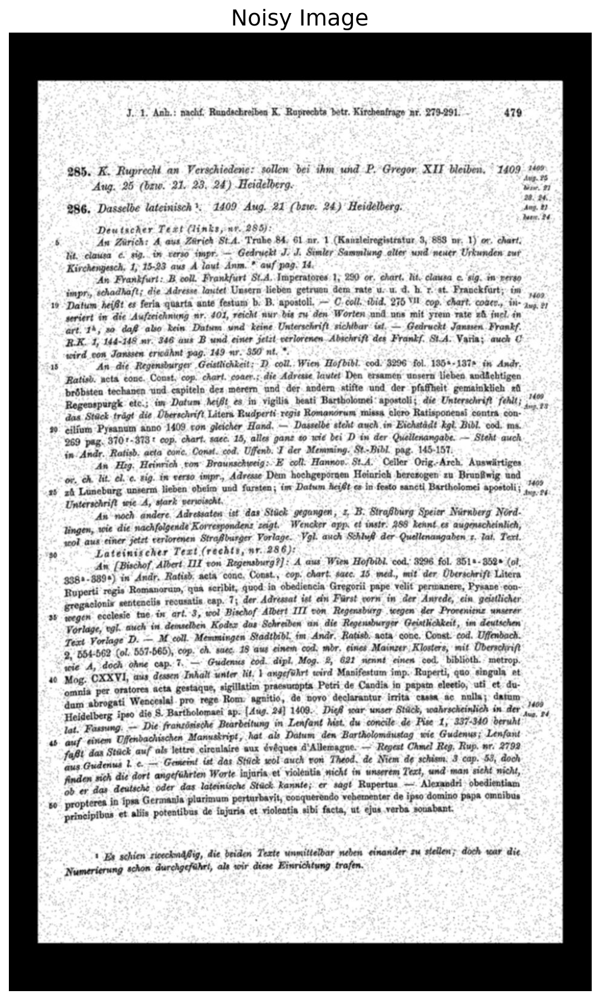

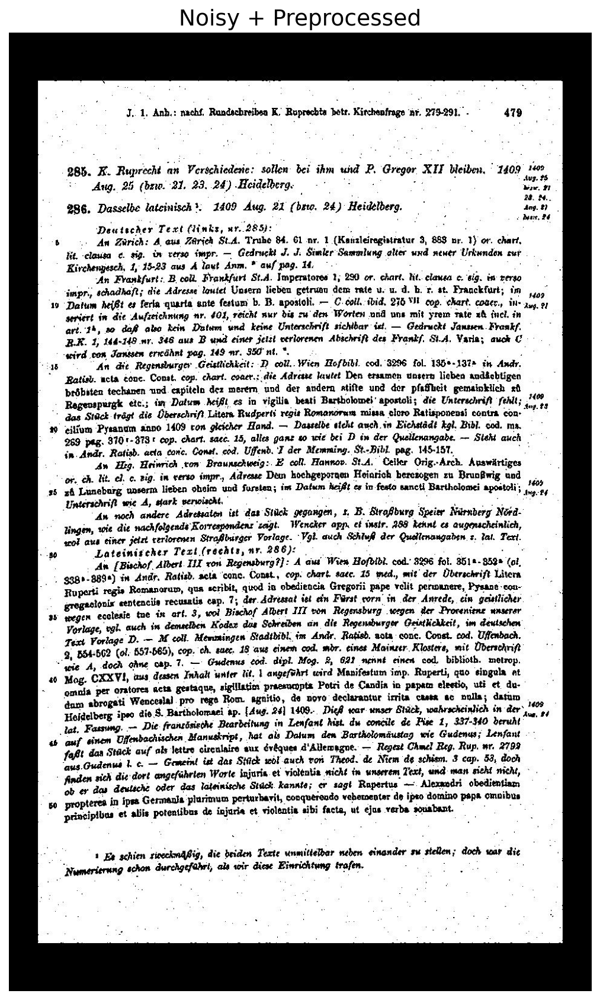

In [89]:
from PIL import Image
import matplotlib.pyplot as plt

test_page = 490

noisy_img = Image.open(f"corrupted_images/{test_page}.jpg").convert("RGB")
preprocessed_img = Image.open(f"corrupted_preprocessed_images/{test_page}.jpg")

plt.figure(figsize=(10,14), dpi=150)
plt.imshow(noisy_img)
plt.title("Noisy Image", fontsize=18)
plt.axis("off")
plt.show()

plt.figure(figsize=(10,14), dpi=150)
plt.imshow(preprocessed_img, cmap="gray")
plt.title("Noisy + Preprocessed", fontsize=18)
plt.axis("off")
plt.show()

### Run GPT model

In [90]:
for p in pages:
    print(f"\n==============================")
    print(f"Page {p}")
    print(f"==============================")

    image_path = f"corrupted_preprocessed_images/{p}.jpg"
    output_path = os.path.join(output_dir_4, f"page_{p}.txt")

    output_text = run_ocr_one_image(image_path, prompt_text_0)

    print(output_text)

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(output_text)

    print(f"Saved: {output_path}")


Page 8
Vorwort.

Das Jahr 1885 brachte die erste Fortsetzung des K. Ruprechts mit dem zweiten
Bande, von dessen Regierung, den fünfson der ganzen Reihe. Im Jahr 1887 wurde
die dritte Abtheilung der Zeit K. Sigmund's ausgegeben, der neunte Band der Reichs-
tagsacten. Jetzt nach einem Jahre können wir bereits den sechsten Band mittheilen,
welcher zugleich der dritte und Schlußband K. Ruprechts ist. Hiermit schließt sich die
Lücke, welche in der Regierung dieses Königs noch übrigblieb vor, und die sämmt-
lichen bisher erschienenen neun Bände bilden eine ununterbrochene Kette. Mit dem
zehnten Bande, dessen Ausgabe das nächste sein wird, soll dann auch die Periode K.
Sigmund's zu ihrem Ende kommen.

I. Bearbeitung des vorliegenden Bandes.

Die Leitung des Urkundenwesens ruht wie bisher in der Hand H. v. Sybel's. Von
früheren Mitarbeitern des Bandes, welche bei den Vorarbeiten wiederholt sowie ins-
besondere bei der Anfertigung von Regesten Auskunft und Abschriften thätig waren,
sind zu nen

### Evaluation -Experiment 4

In [106]:
def normalize_text(text):
    text = text.lower()
    text = text.strip()
    text = re.sub(r"\s+", " ", text)
    return text

In [107]:
results_exp4 = []

gold_base = "https://nlp.fi.muni.cz/projekty/ahisto/ocr-output/494/"

for p in pages:
    print(f"Evaluating Experiment 4 - page {p}...")

    
    gold_url = f"{gold_base}{p}.txt"
    gold_text = requests.get(gold_url).text

    pred_path = os.path.join(output_dir_4, f"page_{p}.txt")
    with open(pred_path, "r", encoding="utf-8") as f:
        pred_text = f.read()

    gold_norm = normalize_text(gold_text)
    pred_norm = normalize_text(pred_text)


    wer_score = wer(gold_norm, pred_norm)
    cer_score = cer(gold_norm, pred_norm)

    results_exp4.append({
        "page": p,
        "WER": wer_score,
        "CER": cer_score
    })

Evaluating Experiment 4 - page 8...
Evaluating Experiment 4 - page 9...
Evaluating Experiment 4 - page 12...
Evaluating Experiment 4 - page 38...
Evaluating Experiment 4 - page 53...
Evaluating Experiment 4 - page 78...
Evaluating Experiment 4 - page 94...
Evaluating Experiment 4 - page 105...
Evaluating Experiment 4 - page 114...
Evaluating Experiment 4 - page 115...
Evaluating Experiment 4 - page 210...
Evaluating Experiment 4 - page 314...
Evaluating Experiment 4 - page 316...
Evaluating Experiment 4 - page 384...
Evaluating Experiment 4 - page 457...
Evaluating Experiment 4 - page 468...
Evaluating Experiment 4 - page 490...
Evaluating Experiment 4 - page 619...
Evaluating Experiment 4 - page 615...
Evaluating Experiment 4 - page 753...


In [108]:
print("=== Experiment 4 Results - GPT5.4 ===")
df_exp4 = pd.DataFrame(results_exp4)
df_exp4

=== Experiment 4 Results - GPT5.4 ===


,page,WER,CER
0,8,0.081886,0.041667
1,9,0.081851,0.019470
2,12,0.089202,0.029027
3,38,0.357567,0.142968
4,53,0.625850,0.424682
5,78,0.280576,0.121644
6,94,0.441077,0.210811
7,105,0.261860,0.131487
8,114,0.156398,0.054367
9,115,0.094617,0.044389


In [110]:
mean_wer_exp4 = df_exp4["WER"].mean()
mean_cer_exp4 = df_exp4["CER"].mean()

print("=== Experiment 4 Results ===")
print(f"Mean WER: {mean_wer_exp4:.4f}")
print(f"Mean CER: {mean_cer_exp4:.4f}")

=== Experiment 4 Results ===
Mean WER: 0.2005
Mean CER: 0.0908


#### Save result

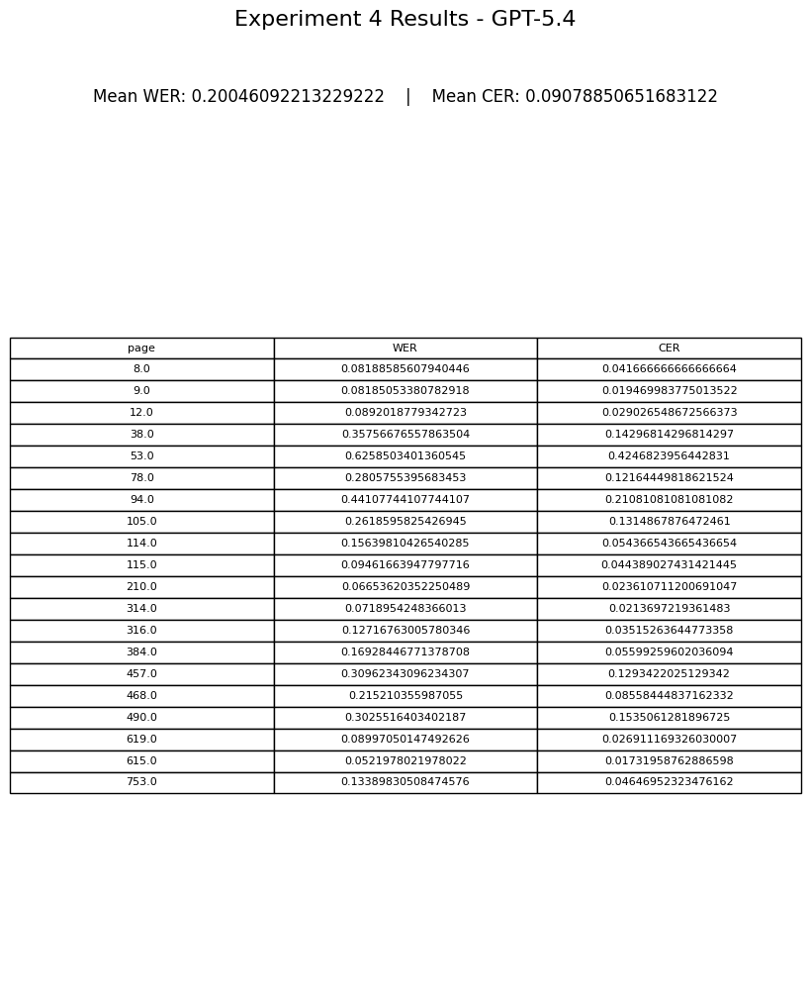

Saved: outputs/Results\experiment_4_results.png


In [111]:
import os
import matplotlib.pyplot as plt

mean_wer = df_exp4["WER"].mean()
mean_cer = df_exp4["CER"].mean()

save_path = os.path.join(output_dir_result_1, "experiment_4_results.png")

fig, ax = plt.subplots(figsize=(10, len(df_exp4) * 0.45 + 2))
ax.axis("off")


fig.suptitle("Experiment 4 Results - GPT-5.4", fontsize=16, y=0.98)

summary_text = f"Mean WER: {mean_wer}    |    Mean CER: {mean_cer}"
fig.text(0.5, 0.90, summary_text, ha="center", va="center", fontsize=12)


table = ax.table(
    cellText=df_exp4.values,
    colLabels=df_exp4.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.3)

ax.set_position([0.1, 0.08, 0.8, 0.78])

fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

print("Saved:", save_path)

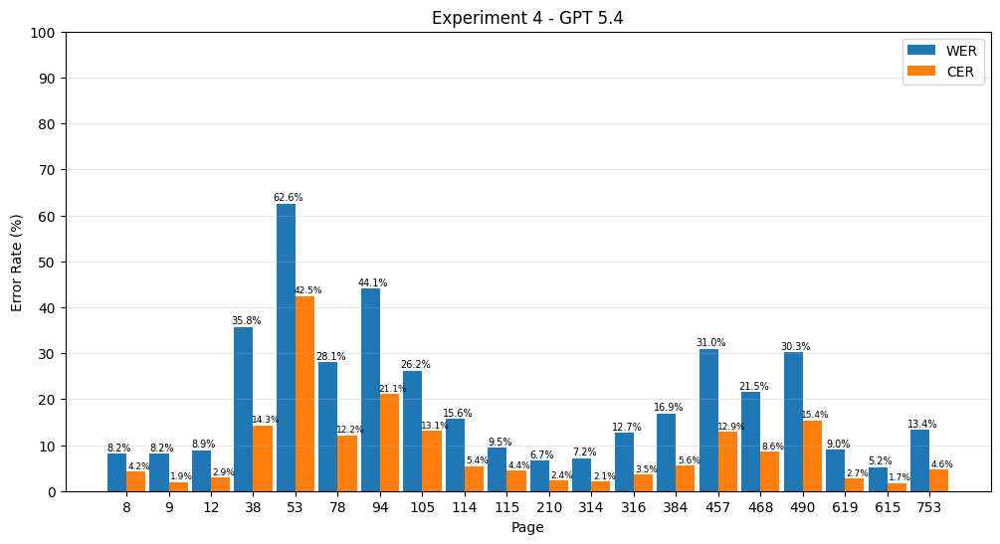

In [113]:
import numpy as np
x = np.arange(len(df_exp4))
width = 0.45

wer_pct = df_exp4["WER"] * 100
cer_pct = df_exp4["CER"] * 100

plt.figure(figsize=(12,6))

bars1 = plt.bar(x - width/2, wer_pct, width, label="WER")
bars2 = plt.bar(x + width/2, cer_pct, width, label="CER")

for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.06,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=7
    )
for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.08,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=6.5
    )

plt.xticks(x, df_exp4["page"])
plt.xlabel("Page")
plt.ylabel("Error Rate (%)")
plt.title("Experiment 4 - GPT 5.4")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.ylim(0, 100)
plt.yticks(np.arange(0, 101, 10))

os.makedirs(output_dir_result_1, exist_ok=True)

plt.savefig(
    os.path.join(
        output_dir_result_1,
        "experiment_4_wer_cer_by_page.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

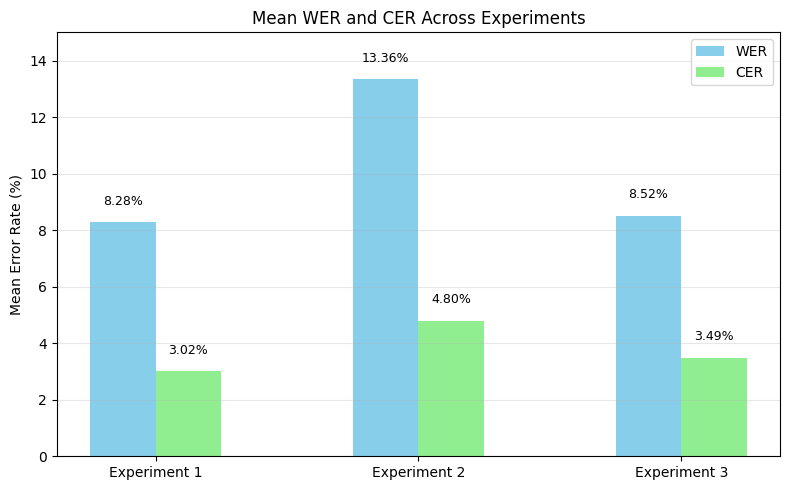

In [85]:
import matplotlib.pyplot as plt
import numpy as np


mean_wer = [
    df_exp1["WER"].mean() * 100,
    df_exp2["WER"].mean() * 100,
    df_exp3["WER"].mean() * 100
]

mean_cer = [
    df_exp1["CER"].mean() * 100,
    df_exp2["CER"].mean() * 100,
    df_exp3["CER"].mean() * 100
]

experiments = [
    "Experiment 1",
    "Experiment 2",
    "Experiment 3"
]
x = np.arange(len(experiments))
width = 0.25        

plt.figure(figsize=(8,5))

bars1 = plt.bar(
    x - width/2,
    mean_wer,
    width,
    color="skyblue",
    label="WER"
)

bars2 = plt.bar(
    x + width/2,
    mean_cer,
    width,
    color="lightgreen",
    label="CER"
)


for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.xticks(x, experiments)
plt.ylabel("Mean Error Rate (%)")
plt.title("Mean WER and CER Across Experiments")

plt.yticks(np.arange(0, 16, 2))
plt.ylim(0, 15)

plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.tight_layout()


plt.savefig(
    os.path.join(output_dir_result_1, "three_experiment_summary.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()